# Competitive Auctions on eBay: Classification Trees vs. k-NN
**RSM8413 Machine Learning Analytics, Group Assignment 2 (Fall 2026)**

**Business question.** A seller has an item to list. Will the auction attract **at least two bids** (a *competitive* auction)? And which of the settings the seller controls (opening price, duration, end day, currency/marketplace) make that more likely?

There are two separate goals, and keeping them apart shapes the whole analysis:
1. **Prediction at listing time.** The model may only use information that exists *before* the auction starts.
2. **Seller guidance.** The model has to be interpretable enough to turn into advice, and the advice should focus on levers the seller can actually pull.

**How to run.** Put `eBayAuctions.xlsx` in the same folder as this notebook, then *Kernel → Restart & Run All*. All figures are also saved to `./figures/` for the report.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GroupShuffleSplit)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Settings used throughout (change in ONE place) -------------------------
RANDOM_STATE = 1      # makes the split, the trees and the CV folds reproducible
TEST_SIZE = 0.40      # 60% training / 40% test, as required
MIN_LEAF = 50         # minimum records in a terminal node, as required
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# ---- Plot style: one consistent, colour-blind-safe palette ------------------
CLASS_COLORS = {0: "#f47230", 1: "#257de0"}           # orange = non-competitive, blue = competitive
CLASS_MARKERS = {0: "^", 1: "o"}                       # shape as well as colour (works in B/W print)
CLASS_NAMES = {0: "Non-competitive", 1: "Competitive"}
BAND_COLORS = ("#00b894", "#6a4ce2")                   # aqua / violet for opening-price bands
TEXT, TEXT2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": "#bdbdbd", "axes.labelcolor": TEXT, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": TEXT2, "ytick.color": TEXT2, "legend.frameon": False,
})


def usd(v):
    """Dollar label for plots (a bare '$' would switch matplotlib into math mode)."""
    return f"\\${v:,.2f}"


def savefig(fig, name):
    """Save a figure into ./figures so it can be dropped straight into the report."""
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")

## 1. Load and clean the data

In [2]:
def find_data_file(expected="eBayAuctions.xlsx"):
    """Find the data file in the notebook folder. The name match ignores case,
    because macOS/Windows ignore it but Linux and GitHub do not."""
    for f in os.listdir("."):
        if f.lower() == expected.lower():
            return f
    raise FileNotFoundError(f"Put {expected} in the same folder as this notebook.")


DATA_FILE = find_data_file()
raw = pd.read_excel(DATA_FILE, sheet_name="eBay auctions")
print("Raw sheet shape:", raw.shape)
print("\nLast rows of the sheet (note the summary cells below the data):")
display(raw.tail(4))

Raw sheet shape: (1975, 9)

Last rows of the sheet (note the summary cells below the data):


,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
1971,Automotive,US,145.0,7.0,Sat,999.0,999.0,0.0,NaN
1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,955.0,0.548535
1974,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1741.0,NaN


In [3]:
df = (raw.dropna(subset=["Category"])                      # drops the 3 summary rows under the data
         [["Category", "Currency", "sellerRating", "Duration", "endDay",
           "ClosePrice", "OpenPrice", "Competitive?"]]       # drops the stray 'Unnamed: 8' column
         .rename(columns={"Competitive?": "Competitive", "sellerRating": "SellerRating",
                          "endDay": "EndDay"})
         .reset_index(drop=True))
df = df.astype({"SellerRating": int, "Duration": int, "Competitive": int})

DAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["EndDay"] = pd.Categorical(df["EndDay"], categories=DAY_ORDER, ordered=True)

print(f"Clean data: {df.shape[0]} auctions x {df.shape[1]} columns (the brief says 1,972)")
print("Missing values:", int(df.isna().sum().sum()))
print("Any ClosePrice below OpenPrice?", bool((df.ClosePrice < df.OpenPrice).any()))
print(f"\nShare competitive: {df.Competitive.mean():.1%}  "
      f"({df.Competitive.sum()} competitive / {(1 - df.Competitive).sum()} non-competitive)")
display(df.head())

Clean data: 1972 auctions x 8 columns (the brief says 1,972)
Missing values: 0
Any ClosePrice below OpenPrice? False

Share competitive: 54.1%  (1066 competitive / 906 non-competitive)


,Category,Currency,SellerRating,Duration,EndDay,ClosePrice,OpenPrice,Competitive
0,Music/Movie/Game,US,37727,7,Mon,0.01,0.01,0
1,Music/Movie/Game,US,37727,7,Mon,4.26,0.01,1
2,SportingGoods,US,34343,1,Fri,0.11,0.01,1
3,SportingGoods,US,27132,5,Mon,17.01,0.99,1
4,SportingGoods,US,27132,5,Mon,19.02,0.99,1


## 2. Understand the data before modelling
Four questions to answer before fitting anything:
**(a)** What do the raw patterns look like? **(b)** Is any variable *only known after* the auction ends (leakage)? **(c)** Are the prices comparable across currencies? **(d)** Is the dataset dominated by a few sellers? That would affect both how we evaluate the models and how far we can trust the "effects".

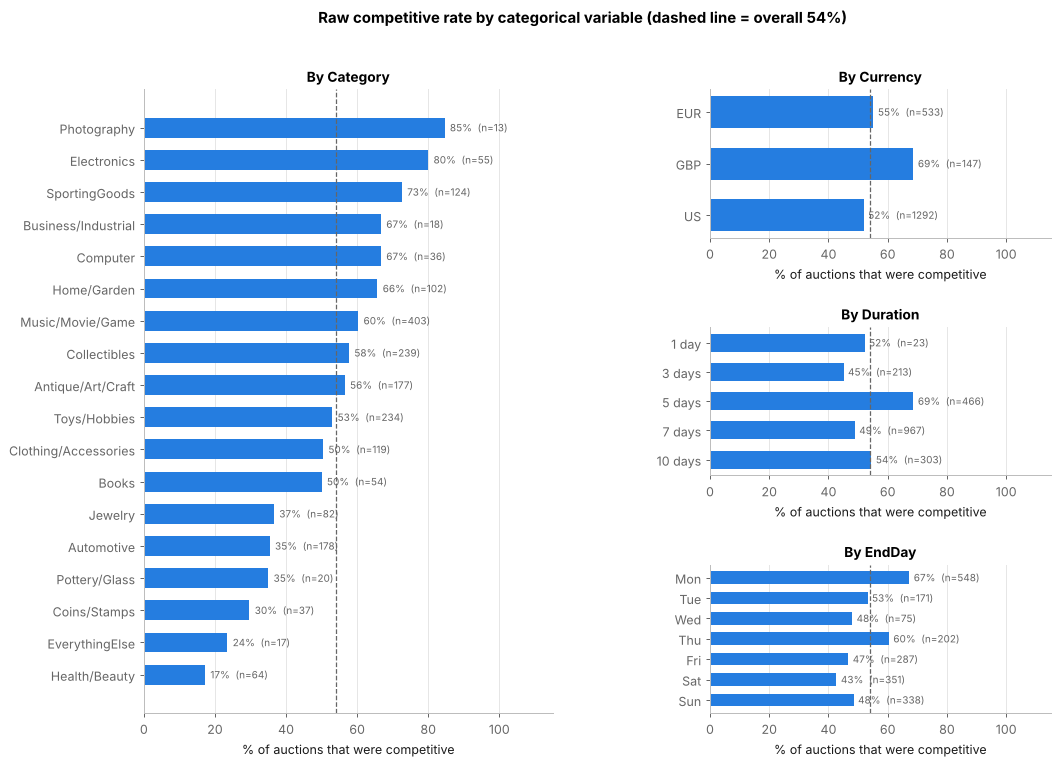

In [4]:
def rate_table(data, col):
    t = data.groupby(col, observed=True)["Competitive"].agg(Auctions="size", PctCompetitive="mean")
    t["PctCompetitive"] = (100 * t["PctCompetitive"]).round(1)
    return t


overall = 100 * df.Competitive.mean()
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(3, 2, width_ratios=[1.2, 1], hspace=0.6, wspace=0.42)
panels = [("Category", gs[:, 0]), ("Currency", gs[0, 1]), ("Duration", gs[1, 1]), ("EndDay", gs[2, 1])]
for col, spec in panels:
    ax = fig.add_subplot(spec)
    t = rate_table(df, col)
    if col == "Category":
        t = t.sort_values("PctCompetitive")
    else:
        t = t.iloc[::-1]                                       # first level on top
    labels = [f"{i} day{'s' if i > 1 else ''}" if col == "Duration" else str(i) for i in t.index]
    ax.barh(labels, t["PctCompetitive"], color=CLASS_COLORS[1], height=0.62)
    ax.axvline(overall, color=TEXT2, ls="--", lw=1)
    for y_pos, (v, n) in enumerate(zip(t["PctCompetitive"], t["Auctions"])):
        ax.text(v + 1.5, y_pos, f"{v:.0f}%  (n={n})", va="center", fontsize=8, color=TEXT2)
    ax.set_xlim(0, 115)
    ax.set_xlabel("% of auctions that were competitive")
    ax.set_title(f"By {col}")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Raw competitive rate by categorical variable (dashed line = overall {overall:.0f}%)",
             fontweight="bold", y=0.98)
savefig(fig, "01_rate_by_categorical.png")
plt.show()

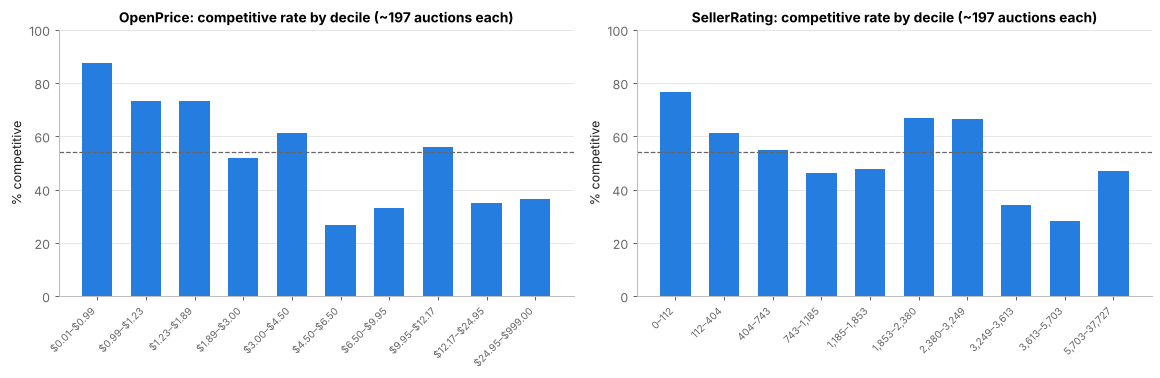

       SellerRating  OpenPrice  ClosePrice
count       1972.00    1972.00     1972.00
mean        3560.24      12.93       36.45
std         5973.01      38.86       89.49
min            0.00       0.01        0.01
25%          595.00       1.23        4.91
50%         1853.00       4.50       10.00
75%         3380.00       9.99       28.00
max        37727.00     999.00      999.00


In [5]:
def binned_rate(series, n_bins=10, money=True):
    bins = pd.qcut(series, n_bins, duplicates="drop")
    t = df.groupby(bins, observed=True)["Competitive"].agg(Auctions="size", PctCompetitive="mean")
    fmt = usd if money else (lambda v: f"{v:,.0f}")
    t.index = [f"{fmt(max(iv.left, series.min()))}–{fmt(iv.right)}" for iv in t.index]
    t["PctCompetitive"] *= 100
    return t


fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, (col, money) in zip(axes, [("OpenPrice", True), ("SellerRating", False)]):
    t = binned_rate(df[col], money=money)
    ax.bar(range(len(t)), t["PctCompetitive"], color=CLASS_COLORS[1], width=0.62)
    ax.axhline(overall, color=TEXT2, ls="--", lw=1)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% competitive")
    ax.set_title(f"{col}: competitive rate by decile (~197 auctions each)")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "02_rate_by_numeric_decile.png")
plt.show()

print(df[["SellerRating", "OpenPrice", "ClosePrice"]].describe().round(2))

**(b) Leakage check: ClosePrice.** ClosePrice is only known *after* the auction closes. When only one bid arrives, eBay closes at the opening price. So "ClosePrice > OpenPrice" is close to the definition of a competitive auction.

Competitive,Competitive,Non-competitive
row_0,,
ClosePrice = OpenPrice,38,844
ClosePrice > OpenPrice,1028,62


The one-line rule 'competitive if ClosePrice > OpenPrice' is right for 94.9% of all auctions.
About 100 auctions contradict the rule. These look like label noise, which caps how well any model can do.


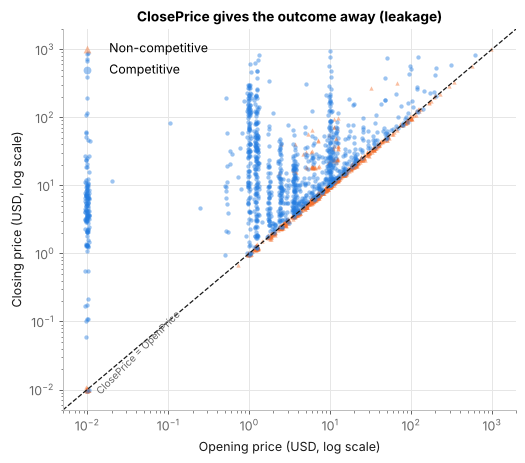

In [6]:
close_above_open = df.ClosePrice > df.OpenPrice
leak_table = pd.crosstab(close_above_open.map({True: "ClosePrice > OpenPrice", False: "ClosePrice = OpenPrice"}),
                         df.Competitive.map(CLASS_NAMES))
display(leak_table)
print(f"The one-line rule 'competitive if ClosePrice > OpenPrice' is right for "
      f"{(close_above_open.astype(int) == df.Competitive).mean():.1%} of all auctions.")
print(f"About {(close_above_open.astype(int) != df.Competitive).sum()} auctions contradict the rule. "
      "These look like label noise, which caps how well any model can do.")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
rng_plot = np.random.default_rng(0)
for cls in [0, 1]:
    d = df[df.Competitive == cls]
    jitter = np.exp(rng_plot.normal(0, 0.03, size=(2, len(d))))
    ax.scatter(d.OpenPrice * jitter[0], d.ClosePrice * jitter[1], s=12, alpha=0.45,
               marker=CLASS_MARKERS[cls], color=CLASS_COLORS[cls], label=CLASS_NAMES[cls], linewidths=0)
lims = [0.005, 2000]
ax.plot(lims, lims, color=TEXT, lw=1, ls="--")
ax.text(0.012, 0.0085, "ClosePrice = OpenPrice", rotation=45, fontsize=8, color=TEXT2)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="Opening price (USD, log scale)", ylabel="Closing price (USD, log scale)",
       title="ClosePrice gives the outcome away (leakage)")
ax.legend(loc="upper left", markerscale=1.8)
savefig(fig, "03_leakage_close_vs_open.png")
plt.show()

**(c) Are prices in different currencies?** The data description says prices are "in the currency" of the listing, but the most common EUR and GBP opening prices are exactly €1 / €2 / £1 converted to USD. They are the round numbers sellers actually choose.

In [7]:
fx_check = []
for cur, rate in [("EUR", 1.2298), ("GBP", 1.77)]:
    top = df.loc[df.Currency == cur, "OpenPrice"].value_counts().head(4)
    for price, n in top.items():
        fx_check.append({"Currency": cur, "OpenPrice in data": price, "Auctions": n,
                         f"OpenPrice / FX rate": round(price / rate, 2)})
display(pd.DataFrame(fx_check))
print("So all prices are already in USD. No conversion is needed, and 'Currency' really\n"
      "identifies the marketplace/country of the listing (US, euro-zone, UK).")

,Currency,OpenPrice in data,Auctions,OpenPrice / FX rate
0,EUR,1.23,200,1.00
1,EUR,2.45,105,1.99
2,EUR,11.07,39,9.00
3,EUR,6.15,24,5.00
4,GBP,1.77,52,1.00
5,GBP,8.91,10,5.03
6,GBP,0.54,9,0.31
7,GBP,4.44,7,2.51


So all prices are already in USD. No conversion is needed, and 'Currency' really
identifies the marketplace/country of the listing (US, euro-zone, UK).


**(d) Sellers and duplicates.** No seller ID is provided, but `SellerRating` is a near-unique seller fingerprint.

In [8]:
n_sellers = df.SellerRating.nunique()
top20_share = df.SellerRating.value_counts().head(20).sum() / len(df)
pre_cols = ["Category", "Currency", "SellerRating", "Duration", "EndDay", "OpenPrice"]
print(f"Distinct seller ratings (≈ sellers): {n_sellers}")
print(f"Share of auctions from the 20 biggest sellers: {top20_share:.1%}")
print(f"Rows identical to another row on all listing-time variables: {df.duplicated(subset=pre_cols).sum()}")

top_sellers = (df.groupby("SellerRating")
                 .agg(Auctions=("Competitive", "size"), PctCompetitive=("Competitive", "mean"),
                      MedianOpen=("OpenPrice", "median"),
                      MainEndDay=("EndDay", lambda s: s.value_counts().index[0]),
                      MainDuration=("Duration", lambda s: s.value_counts().index[0]))
                 .sort_values("Auctions", ascending=False).head(6))
top_sellers["PctCompetitive"] = (100 * top_sellers["PctCompetitive"]).round(1)
display(top_sellers)

confound = (df.groupby("EndDay", observed=True)
              .agg(Auctions=("Competitive", "size"), PctCompetitive=("Competitive", "mean"),
                   MedianOpen=("OpenPrice", "median"),
                   PctOpenAtMost123=("OpenPrice", lambda s: (s <= 1.23).mean()),
                   BiggestSellerShare=("SellerRating", lambda s: s.value_counts(normalize=True).iloc[0])))
for c in ["PctCompetitive", "PctOpenAtMost123", "BiggestSellerShare"]:
    confound[c] = (100 * confound[c]).round(1)
print("\nWho ends auctions on which day? (Is the 'Monday effect' really about the day?)")
display(confound)

Distinct seller ratings (≈ sellers): 461
Share of auctions from the 20 biggest sellers: 41.5%
Rows identical to another row on all listing-time variables: 840


,Auctions,PctCompetitive,MedianOpen,MainEndDay,MainDuration
SellerRating,,,,,
3249,128,87.5,0.01,Mon,5
2349,92,82.6,3.60,Fri,7
3385,82,32.9,3.75,Sat,7
5701,56,41.1,3.07,Mon,10
27132,46,100.0,0.99,Mon,5
1155,44,18.2,7.49,Sun,7



Who ends auctions on which day? (Is the 'Monday effect' really about the day?)


,Auctions,PctCompetitive,MedianOpen,PctOpenAtMost123,BiggestSellerShare
EndDay,,,,,
Mon,548,67.3,2.450,47.8,23.4
Tue,171,53.2,4.900,23.4,14.0
Wed,75,48.0,2.450,41.3,9.3
Thu,202,60.4,2.335,16.8,8.9
Fri,287,46.7,6.950,14.6,10.8
Sat,351,42.7,6.500,14.2,23.4
Sun,338,48.5,7.990,17.2,8.0


### What the exploration means for the strategy
* **ClosePrice is leakage.** A tree that uses it will look strong but cannot be used before an auction starts. We fit it because the brief asks for it, then replace it with a *listing-time* model.
* **Opening price is the strongest legitimate signal.** Auctions that open at \$0.99 or less are competitive about 87% of the time. Above roughly \$4.50, the rate drops to around 27–56%.
* **Raw effects of end day and duration are confounded.** Monday and 5-day auctions *look* better, but they also have much lower opening prices and are dominated by a few large sellers. A multivariable model (the tree) is needed to separate the effects.
* **Prices are already in USD.** Currency acts as a marketplace indicator, so no conversion is needed.
* **Seller clustering.** A random split puts the same seller's near-identical listings in both the training and the test set, which makes test accuracy look better than it would for a *new* seller. We keep the required random split for the main analysis and add a seller-grouped check in Section 7.
* **Label noise.** About 5% of auctions contradict their own prices, so no model will reach 100%.

## 3. Pre-processing
* **Dummy variables** for `Category` (18), `Currency` (3), `EndDay` (7) and `Duration` (5). Duration is treated as categorical, as required. This also lets the tree pick out, say, 5-day auctions on their own.
* We keep **all levels** (no `drop_first`). Dropping a reference level matters for regression (multicollinearity) but not for trees, where every level should be available to split on and rules read more naturally. For k-NN, dropping a level would make distances depend on which level was arbitrarily dropped.
* **No scaling for trees.** Splits depend only on the order of the values, so scaling or log transforms do not change the tree. For **k-NN** (Section 6), `SellerRating` and `OpenPrice` are log-transformed (both are very right-skewed) and standardised *inside a pipeline fitted on the training data only*, so no information leaks from the test set.
* Two predictor sets: **ALL** (includes ClosePrice, for Tree 1) and **LISTING-TIME** (excludes ClosePrice, for Tree 2 and k-NN).

In [9]:
CATEGORICAL = ["Category", "Currency", "EndDay", "Duration"]
NUMERIC = ["SellerRating", "OpenPrice", "ClosePrice"]

X = pd.get_dummies(df[NUMERIC + CATEGORICAL].astype({"EndDay": str}),
                   columns=CATEGORICAL, prefix_sep="_", dtype=int)
y = df["Competitive"]

FEATURES_ALL = list(X.columns)
FEATURES_PRE = [c for c in FEATURES_ALL if c != "ClosePrice"]


def variable_groups(features):
    """Map each original variable to its column(s), e.g. Category -> 18 dummies."""
    groups = {v: [v] for v in NUMERIC if v in features}
    for v in CATEGORICAL:
        groups[v] = [c for c in features if c.startswith(v + "_")]
    return groups


print(f"{len(FEATURES_ALL)} predictor columns in total "
      f"({len(FEATURES_PRE)} without ClosePrice)")
print({v: len(cols) for v, cols in variable_groups(FEATURES_ALL).items()})

36 predictor columns in total (35 without ClosePrice)
{'SellerRating': 1, 'OpenPrice': 1, 'ClosePrice': 1, 'Category': 18, 'Currency': 3, 'EndDay': 7, 'Duration': 5}


## 4. Train/test split (60% / 40%)
The split is **stratified** on the outcome, so both sets keep the same ~54% competitive share. The same split is reused for every model, so the comparisons are fair.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"Training: {len(X_train)} auctions ({y_train.mean():.1%} competitive)")
print(f"Test:     {len(X_test)} auctions ({y_test.mean():.1%} competitive)")

Training: 1183 auctions (54.0% competitive)
Test:     789 auctions (54.1% competitive)


### Helper functions (rules, diagrams, metrics, importance)

In [11]:
def _is_dummy(feature):
    return any(feature.startswith(v + "_") for v in CATEGORICAL)


def _fmt_threshold(feature, t):
    if feature in ("OpenPrice", "ClosePrice"):
        return f"${t:,.2f}"
    return f"{t:,.1f}"


def split_label(feature, t):
    """Readable text for the condition that sends records to the LEFT child."""
    if _is_dummy(feature):
        var, level = feature.split("_", 1)
        level = f"{level} days" if var == "Duration" else level
        return f"{var} ≠ {level}"
    return f"{feature} ≤ {_fmt_threshold(feature, t)}"


def _simplify(conditions):
    """Merge a root-to-leaf path into the shortest equivalent rule."""
    lo, hi, eq, neq, order = {}, {}, {}, {}, []
    for f, went_left, t in conditions:
        if _is_dummy(f):
            var, level = f.split("_", 1)
            level = f"{level} days" if var == "Duration" else level
            if var not in order:
                order.append(var)
            if went_left:
                neq.setdefault(var, []).append(level)
            else:
                eq[var] = level
        else:
            if f not in order:
                order.append(f)
            if went_left:
                hi[f] = min(hi.get(f, np.inf), t)
            else:
                lo[f] = max(lo.get(f, -np.inf), t)
    parts = []
    for v in order:
        if v in eq:
            parts.append(f"{v} = {eq[v]}")
        elif v in neq:
            parts.append(f"{v} ≠ {' / '.join(neq[v])}")
        elif v in lo and v in hi:
            parts.append(f"{_fmt_threshold(v, lo[v])} < {v} ≤ {_fmt_threshold(v, hi[v])}")
        elif v in hi:
            parts.append(f"{v} ≤ {_fmt_threshold(v, hi[v])}")
        else:
            parts.append(f"{v} > {_fmt_threshold(v, lo[v])}")
    return " AND ".join(parts)


def tree_rules(model, X_tr, y_tr):
    """One IF-THEN rule per terminal node, numbered left-to-right like the diagram."""
    tr, names = model.tree_, list(X_tr.columns)
    leaf_of = pd.Series(model.apply(X_tr), index=X_tr.index)
    rows = []

    def walk(node, path):
        if tr.children_left[node] == -1:
            in_leaf = y_tr[leaf_of == node]
            pred = model.classes_[np.argmax(tr.value[node][0])]
            rows.append({"Rule": len(rows) + 1, "IF": _simplify(path),
                         "THEN": CLASS_NAMES[pred], "Training records": len(in_leaf),
                         "% competitive in node": round(100 * in_leaf.mean(), 1)})
            return
        f, t = names[tr.feature[node]], tr.threshold[node]
        walk(tr.children_left[node], path + [(f, True, t)])
        walk(tr.children_right[node], path + [(f, False, t)])

    walk(0, [])
    return pd.DataFrame(rows).set_index("Rule")


def _node_fill(p):
    """White -> blue for competitive-leaning nodes, white -> orange for the opposite."""
    target = np.array(to_rgb(CLASS_COLORS[1] if p >= 0.5 else CLASS_COLORS[0]))
    w = min(1.0, abs(p - 0.5) * 2) * 0.75
    return tuple((1 - w) * np.ones(3) + w * target)


def plot_tree_diagram(model, X_tr, y_tr, title, fname, figsize=(26, 12), fontsize=9):
    paths = model.decision_path(X_tr)
    n_node = np.asarray(paths.sum(axis=0)).ravel()
    comp_node = np.asarray(paths.T @ y_tr.to_numpy()).ravel()
    tr, names = model.tree_, list(X_tr.columns)
    leaves = [i for i in range(tr.node_count) if tr.children_left[i] == -1]
    rule_no = {leaf: k + 1 for k, leaf in enumerate(leaves)}

    fig, ax = plt.subplots(figsize=figsize)
    anns = plot_tree(model, feature_names=names, class_names=["Non-comp", "Comp"],
                     impurity=False, rounded=True, ax=ax, fontsize=fontsize)
    anns = [a for a in anns if "samples =" in a.get_text()]   # node boxes, in node order
    assert len(anns) == tr.node_count
    for i, ann in enumerate(anns):
        assert f"samples = {tr.n_node_samples[i]}" in ann.get_text()
        p = comp_node[i] / n_node[i]
        if i in rule_no:
            pred = CLASS_NAMES[model.classes_[np.argmax(tr.value[i][0])]]
            text = f"Rule {rule_no[i]}\nn = {n_node[i]}\n{p:.0%} competitive\n→ {pred}"
        else:
            text = f"{split_label(names[tr.feature[i]], tr.threshold[i])}\nn = {n_node[i]} · {p:.0%} comp."
        ann.set_text(text)
        ann.get_bbox_patch().set_facecolor(_node_fill(p))
        ann.get_bbox_patch().set_edgecolor("#9a9a9a")
    ax.set_title(title + "\n(each split: condition true → left branch, false → right branch)",
                 fontsize=13)
    savefig(fig, fname)
    plt.show()


def classification_table(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    t = pd.DataFrame(cm, index=["Actual: Non-competitive", "Actual: Competitive"],
                     columns=["Predicted: Non-competitive", "Predicted: Competitive"])
    t["Total"] = t.sum(axis=1)
    t.loc["Total"] = t.sum()
    return t


def metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {"Accuracy": (tp + tn) / len(y_true),
           "Sensitivity (competitive found)": tp / (tp + fn),
           "Specificity (non-competitive found)": tn / (tn + fp),
           "Precision (when we say competitive)": tp / (tp + fp) if tp + fp else np.nan}
    out["AUC"] = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    return out


def grouped_importance(model, X_eval, y_eval, n_repeats=30, seed=RANDOM_STATE):
    """Importance per ORIGINAL variable (all its dummies together):
    - permutation: drop in test accuracy when the variable is shuffled
    - Gini: share of impurity reduction in the fitted tree"""
    rng = np.random.default_rng(seed)
    base = accuracy_score(y_eval, model.predict(X_eval))
    rows = []
    for var, cols in variable_groups(list(X_eval.columns)).items():
        drops = []
        for _ in range(n_repeats):
            Xp = X_eval.copy()
            Xp[cols] = X_eval[cols].to_numpy()[rng.permutation(len(X_eval))]
            drops.append(base - accuracy_score(y_eval, model.predict(Xp)))
        gini = model.feature_importances_[[X_eval.columns.get_loc(c) for c in cols]].sum()
        rows.append({"Variable": var, "Accuracy drop if shuffled (pp)": 100 * np.mean(drops),
                     "± SD (pp)": 100 * np.std(drops), "Gini importance (%)": 100 * gini})
    return (pd.DataFrame(rows).set_index("Variable")
              .sort_values("Accuracy drop if shuffled (pp)", ascending=False).round(2))

## 5a. Tree 1: all predictors (including ClosePrice)

In [12]:
tree_all = DecisionTreeClassifier(min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
tree_all.fit(X_train[FEATURES_ALL], y_train)
print(f"Tree 1: {tree_all.get_n_leaves()} terminal nodes, depth {tree_all.get_depth()}")

rules_all = tree_rules(tree_all, X_train[FEATURES_ALL], y_train)
display(rules_all)

Tree 1: 16 terminal nodes, depth 6


,IF,THEN,Training records,% competitive in node
Rule,,,,
1,OpenPrice ≤ $1.12 AND ClosePrice ≤ $3.69,Competitive,57,64.9
2,$1.12 < OpenPrice ≤ $3.69 AND ClosePrice ≤ $1.74,Non-competitive,50,8.0
3,$1.12 < OpenPrice ≤ $3.69 AND $1.74 < ClosePrice ≤ $2.46,Non-competitive,57,19.3
4,$1.12 < OpenPrice ≤ $3.69 AND $2.46 < ClosePrice ≤ $3.69,Non-competitive,60,40.0
5,OpenPrice ≤ $2.46 AND ClosePrice > $3.69,Competitive,257,100.0
6,$2.46 < OpenPrice ≤ $3.69 AND ClosePrice > $3.69,Competitive,69,94.2
7,$3.69 < OpenPrice ≤ $4.99 AND ClosePrice ≤ $6.63,Non-competitive,63,25.4
8,$4.99 < OpenPrice ≤ $7.97 AND ClosePrice ≤ $6.63,Non-competitive,59,1.7
9,$3.69 < OpenPrice ≤ $7.97 AND $6.63 < ClosePrice ≤ $10.06,Non-competitive,51,47.1


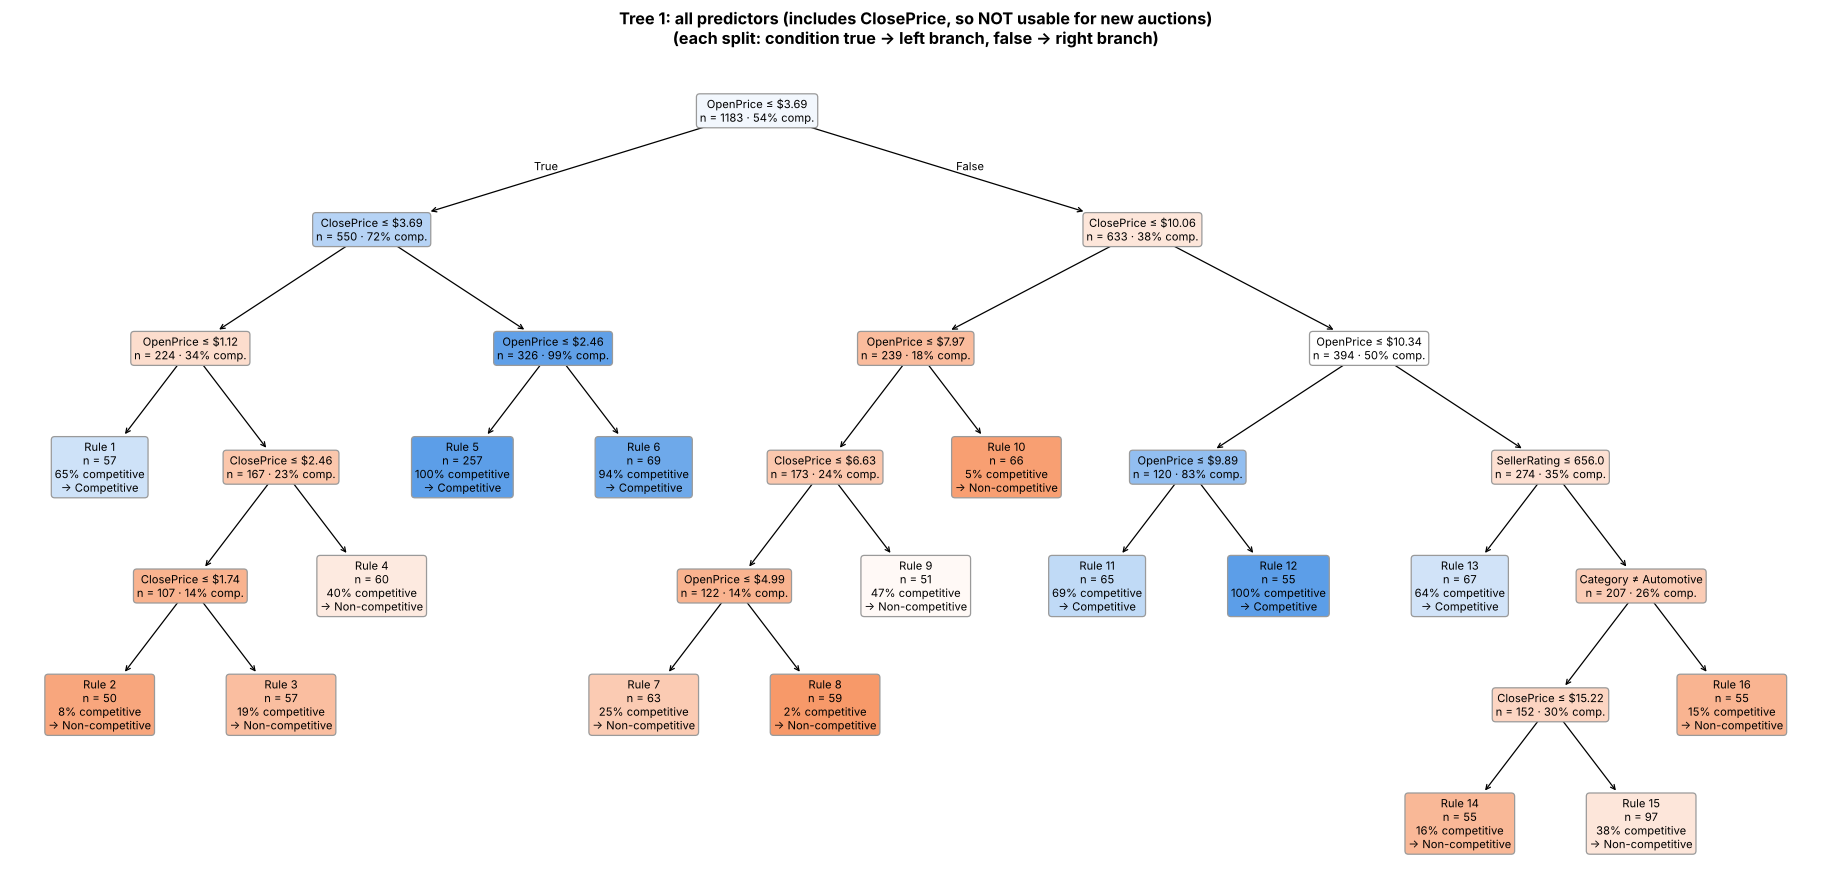

In [13]:
plot_tree_diagram(tree_all, X_train[FEATURES_ALL], y_train,
                  "Tree 1: all predictors (includes ClosePrice, so NOT usable for new auctions)",
                  "04_tree1_all_predictors.png")

In [14]:
perf_all = pd.DataFrame({
    "Training": metrics(y_train, tree_all.predict(X_train[FEATURES_ALL]),
                        tree_all.predict_proba(X_train[FEATURES_ALL])[:, 1]),
    "Test": metrics(y_test, tree_all.predict(X_test[FEATURES_ALL]),
                    tree_all.predict_proba(X_test[FEATURES_ALL])[:, 1])}).round(3)
display(perf_all)
print("Test classification table, Tree 1:")
display(classification_table(y_test, tree_all.predict(X_test[FEATURES_ALL])))

rule_pred = (X_test.ClosePrice > X_test.OpenPrice).astype(int)
print(f"For comparison, the one-line rule 'ClosePrice > OpenPrice' scores "
      f"{accuracy_score(y_test, rule_pred):.1%} on the same test set.")

,Training,Test
Accuracy,0.827,0.820
Sensitivity (competitive found),0.786,0.789
Specificity (non-competitive found),0.875,0.856
Precision (when we say competitive),0.881,0.866
AUC,0.912,0.892


Test classification table, Tree 1:


,Predicted: Non-competitive,Predicted: Competitive,Total
Actual: Non-competitive,310,52,362
Actual: Competitive,90,337,427
Total,400,389,789


For comparison, the one-line rule 'ClosePrice > OpenPrice' scores 95.6% on the same test set.


**Which variables could we drop?** Importance is measured per *original* variable (all 18 Category dummies count together), and the permutation version is computed on the *test* set.

In [15]:
imp_all = grouped_importance(tree_all, X_test[FEATURES_ALL], y_test)
display(imp_all)

top3 = list(imp_all.index[:3])
cols_top3 = [c for v in top3 for c in variable_groups(FEATURES_ALL)[v]]
tree_top3 = DecisionTreeClassifier(min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
tree_top3.fit(X_train[cols_top3], y_train)
print(f"Tree with only {top3}: test accuracy {accuracy_score(y_test, tree_top3.predict(X_test[cols_top3])):.1%} "
      f"vs. {accuracy_score(y_test, tree_all.predict(X_test[FEATURES_ALL])):.1%} with all {len(FEATURES_ALL)} columns.")

,Accuracy drop if shuffled (pp),± SD (pp),Gini importance (%)
Variable,,,
OpenPrice,24.20,1.28,43.56
ClosePrice,18.52,1.24,51.06
SellerRating,3.73,0.90,4.73
Category,0.00,0.00,0.64
Currency,0.00,0.00,0.00
EndDay,0.00,0.00,0.00
Duration,0.00,0.00,0.00


Tree with only ['OpenPrice', 'ClosePrice', 'SellerRating']: test accuracy 82.0% vs. 82.0% with all 36 columns.


### Reading Tree 1
**Obvious (uninteresting) rules.** Most of the tree compares ClosePrice with OpenPrice. Rules 5, 6 and 12 say that when the auction closed well above its opening price it was competitive (94–100%). Rules 2, 8 and 10 say that when it closed at or near the opening price it had a single bid (2–8% competitive). Both are close to the *definition* of a competitive auction, because a price only rises above the opening price if someone is outbid.

**Interesting / unexpected.**
* **Opening price is the root split (≤ \$3.69), ahead of ClosePrice.** Cheap starts go with competition even before the outcome is known.
* **16 rules do worse than 1.** A single rule, "competitive if ClosePrice > OpenPrice", scores 95.6% on the test set against the tree's 82.0%. A tree can only split one variable at a time, so it approximates the diagonal boundary in Figure 3 with a staircase. Lesson: when the signal is a *relationship* between two variables, a derived feature (difference or ratio) beats a deeper tree.
* **Seller rating and category appear only among expensive items.** Low-rated sellers (≤ 656) still get competitive auctions 64% of the time (Rule 13), while Automotive is singled out as non-competitive (Rule 16, 15%). Those are high-value items with few interested bidders.
* Currency, end day and duration are not used at all once prices are known.

**Reducing the number of predictors.** OpenPrice, ClosePrice and SellerRating account for all of the measurable importance. A tree with only these three gives the same 82.0% test accuracy as all 36 columns. If a fourth were wanted for presentation, Category is the only other variable the tree uses.

**Is this model practical for a new auction? No.** ClosePrice is only known once the auction has ended, and by then the seller already knows whether two bids arrived. This is *target leakage*: the model answers a question nobody needs to ask. Tree 2 removes it.

## 5b. Tree 2: listing-time predictors only (no ClosePrice)
These predictors are all known when the seller creates the listing: category, currency/marketplace, seller rating, duration, end day (start day + duration) and opening price.

In [16]:
tree_pre = DecisionTreeClassifier(min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
tree_pre.fit(X_train[FEATURES_PRE], y_train)
print(f"Tree 2: {tree_pre.get_n_leaves()} terminal nodes, depth {tree_pre.get_depth()}")

rules_pre = tree_rules(tree_pre, X_train[FEATURES_PRE], y_train)
display(rules_pre)

Tree 2: 16 terminal nodes, depth 7


,IF,THEN,Training records,% competitive in node
Rule,,,,
1,OpenPrice ≤ $1.12 AND Duration ≠ 5 days,Competitive,54,81.5
2,OpenPrice ≤ $1.12 AND Duration = 5 days,Competitive,123,91.9
3,"$1.12 < OpenPrice ≤ $3.69 AND SellerRating ≤ 2,403.5 AND Currency ≠ EUR",Competitive,106,82.1
4,$1.12 < OpenPrice ≤ $2.45 AND SellerRating ≤ 582.0 AND Currency = EUR,Competitive,57,78.9
5,"$1.12 < OpenPrice ≤ $2.45 AND 582.0 < SellerRating ≤ 2,403.5 AND Currency = EUR",Competitive,58,65.5
6,"$2.45 < OpenPrice ≤ $3.69 AND SellerRating ≤ 2,403.5 AND Currency = EUR",Competitive,60,60.0
7,"$1.12 < OpenPrice ≤ $3.69 AND SellerRating > 2,403.5",Non-competitive,92,38.0
8,OpenPrice > $3.69 AND SellerRating ≤ 214.0,Competitive,75,72.0
9,OpenPrice > $3.69 AND 214.0 < SellerRating ≤ 562.0,Competitive,58,58.6


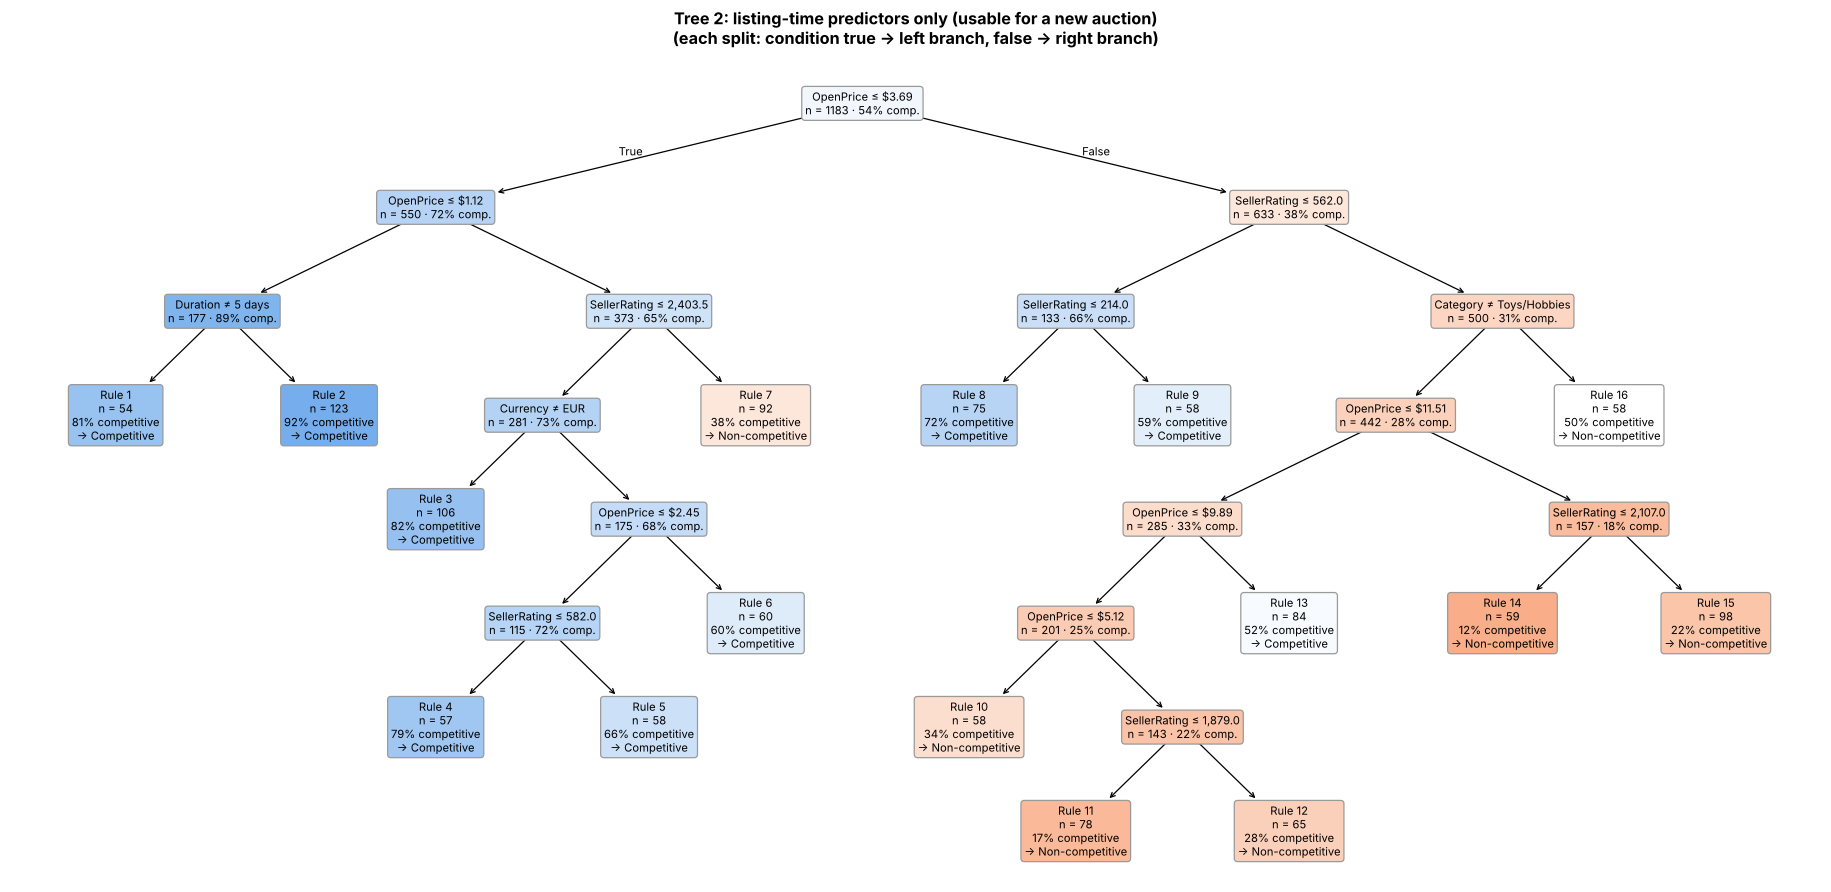

In [17]:
plot_tree_diagram(tree_pre, X_train[FEATURES_PRE], y_train,
                  "Tree 2: listing-time predictors only (usable for a new auction)",
                  "05_tree2_listing_time.png")

### Tree 2 on a scatter plot of its two quantitative predictors
Solid lines show splits on OpenPrice or SellerRating that apply to everything in their region. Dashed lines show splits that only apply to a subgroup defined by a categorical variable (for example, euro-zone listings only). The axes use log scales because both variables are heavily skewed. Points are jittered slightly so stacked duplicates stay visible.

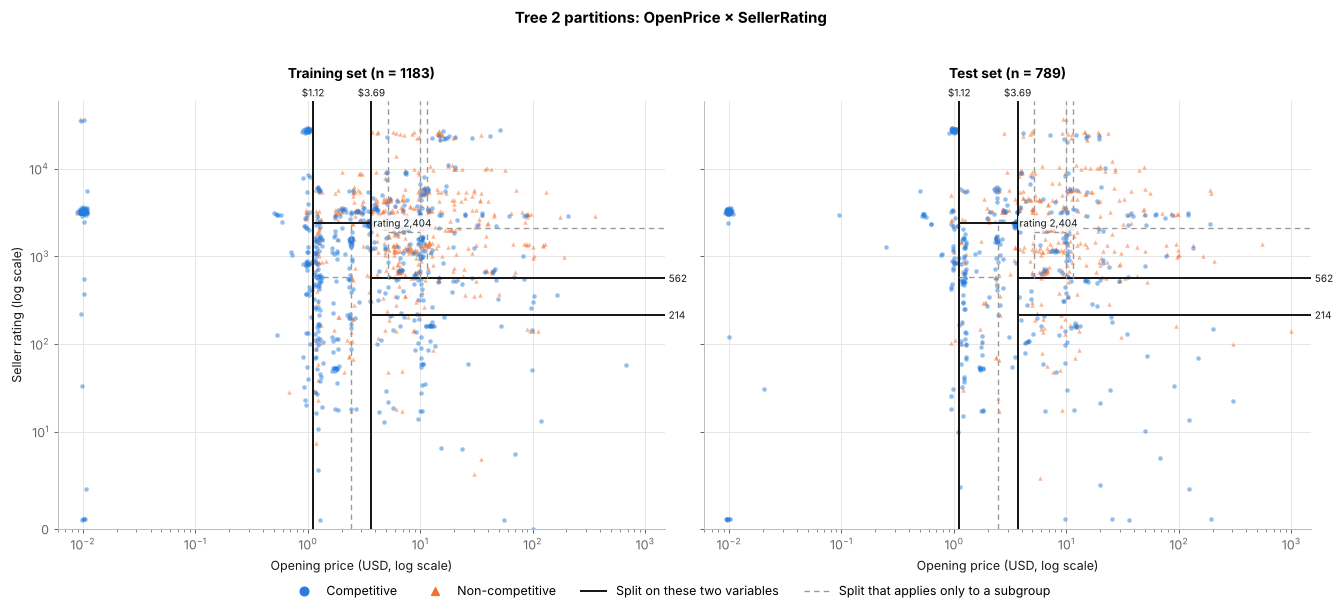

Tree using only OpenPrice + SellerRating: test accuracy 72.8% (Tree 2 with all listing-time predictors: 72.0%)


In [18]:
def draw_partition(ax, model, names, xf, yf, bounds, node=0, conditional=False, labels=None):
    tr = model.tree_
    if tr.children_left[node] == -1:
        return
    f, t = names[tr.feature[node]], tr.threshold[node]
    x0, x1, y0, y1 = bounds
    style = dict(color="#9a9a9a", lw=1.1, ls=(0, (4, 3))) if conditional else dict(color=TEXT, lw=1.6)
    L, R = tr.children_left[node], tr.children_right[node]
    if f == xf:
        ax.plot([t, t], [y0, y1], **style, zorder=3)
        if labels is not None and not conditional:
            labels.append(("x", t, y1, x0, x1))
        draw_partition(ax, model, names, xf, yf, (x0, t, y0, y1), L, conditional, labels)
        draw_partition(ax, model, names, xf, yf, (t, x1, y0, y1), R, conditional, labels)
    elif f == yf:
        ax.plot([x0, x1], [t, t], **style, zorder=3)
        if labels is not None and not conditional:
            labels.append(("y", t, x1, y0, y1))
        draw_partition(ax, model, names, xf, yf, (x0, x1, y0, t), L, conditional, labels)
        draw_partition(ax, model, names, xf, yf, (x0, x1, t, y1), R, conditional, labels)
    else:                                   # split on a categorical dummy: both children, same region
        draw_partition(ax, model, names, xf, yf, bounds, L, True, labels)
        draw_partition(ax, model, names, xf, yf, bounds, R, True, labels)


XLIM, YLIM = (0.006, 1500), (0, 60000)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.3), sharey=True)
for ax, (Xs, ys, name) in zip(axes, [(X_train, y_train, "Training set"), (X_test, y_test, "Test set")]):
    rng_plot = np.random.default_rng(0)
    for cls in [0, 1]:
        d = Xs[ys == cls]
        jit = np.exp(rng_plot.normal(0, 0.04, size=(2, len(d))))
        ax.scatter(d.OpenPrice * jit[0], d.SellerRating * jit[1], s=13, alpha=0.5, linewidths=0,
                   marker=CLASS_MARKERS[cls], color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
    lab = []
    draw_partition(ax, tree_pre, FEATURES_PRE, "OpenPrice", "SellerRating",
                   (XLIM[0], XLIM[1], YLIM[0], YLIM[1]), labels=lab)
    box = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
    for kind, t, end, *_ in lab:                   # label each solid line at the end of its segment
        if kind == "x":
            if end >= YLIM[1]:
                ax.text(t, YLIM[1] * 1.05, usd(t), ha="center", va="bottom", fontsize=8, color=TEXT)
            else:
                ax.text(t, end, usd(t), ha="center", va="bottom", fontsize=8, color=TEXT, bbox=box)
        else:
            if end >= XLIM[1]:
                ax.text(XLIM[1] * 1.08, t, f"{t:,.0f}", ha="left", va="center", fontsize=8, color=TEXT)
            else:
                ax.text(end * 1.04, t, f"rating {t:,.0f}", ha="left", va="center", fontsize=8,
                        color=TEXT, bbox=box)
    ax.set_xscale("log")
    ax.set_yscale("symlog", linthresh=10)
    ax.set(xlim=XLIM, ylim=YLIM, xlabel="Opening price (USD, log scale)")
    ax.set_title(f"{name} (n = {len(Xs)})", pad=18)
axes[0].set_ylabel("Seller rating (log scale)")
handles = [Line2D([], [], marker=CLASS_MARKERS[c], color=CLASS_COLORS[c], ls="", markersize=7,
                  label=CLASS_NAMES[c]) for c in [1, 0]]
handles += [Line2D([], [], color=TEXT, lw=1.6, label="Split on these two variables"),
            Line2D([], [], color="#9a9a9a", lw=1.1, ls=(0, (4, 3)), label="Split that applies only to a subgroup")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Tree 2 partitions: OpenPrice × SellerRating", fontweight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "06_tree2_scatter_partition.png")
plt.show()

cols_2 = ["OpenPrice", "SellerRating"]
tree_two = DecisionTreeClassifier(min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
tree_two.fit(X_train[cols_2], y_train)
print(f"Tree using only OpenPrice + SellerRating: test accuracy "
      f"{accuracy_score(y_test, tree_two.predict(X_test[cols_2])):.1%} "
      f"(Tree 2 with all listing-time predictors: "
      f"{accuracy_score(y_test, tree_pre.predict(X_test[FEATURES_PRE])):.1%})")

### Classification tables for Tree 2

In [19]:
pred_pre_train = tree_pre.predict(X_train[FEATURES_PRE])
pred_pre_test = tree_pre.predict(X_test[FEATURES_PRE])
prob_pre_test = tree_pre.predict_proba(X_test[FEATURES_PRE])[:, 1]

print("Training set:")
display(classification_table(y_train, pred_pre_train))
print("Test set (the honest estimate):")
display(classification_table(y_test, pred_pre_test))

naive_acc = (y_test == y_train.mode()[0]).mean()
perf_pre = pd.DataFrame({
    "Training": metrics(y_train, pred_pre_train, tree_pre.predict_proba(X_train[FEATURES_PRE])[:, 1]),
    "Test": metrics(y_test, pred_pre_test, prob_pre_test)}).round(3)
display(perf_pre)
print(f"Naive benchmark (always predict 'Competitive', the training majority): {naive_acc:.1%} test accuracy")
print(f"Tree 2 cuts the test error rate from {1 - naive_acc:.1%} to "
      f"{1 - perf_pre.loc['Accuracy', 'Test']:.1%}.")

imp_pre = grouped_importance(tree_pre, X_test[FEATURES_PRE], y_test)
display(imp_pre)

Training set:


,Predicted: Non-competitive,Predicted: Competitive,Total
Actual: Non-competitive,364,180,544
Actual: Competitive,144,495,639
Total,508,675,1183


Test set (the honest estimate):


,Predicted: Non-competitive,Predicted: Competitive,Total
Actual: Non-competitive,237,125,362
Actual: Competitive,96,331,427
Total,333,456,789


,Training,Test
Accuracy,0.726,0.720
Sensitivity (competitive found),0.775,0.775
Specificity (non-competitive found),0.669,0.655
Precision (when we say competitive),0.733,0.726
AUC,0.796,0.774


Naive benchmark (always predict 'Competitive', the training majority): 54.1% test accuracy
Tree 2 cuts the test error rate from 45.9% to 28.0%.


,Accuracy drop if shuffled (pp),± SD (pp),Gini importance (%)
Variable,,,
OpenPrice,16.25,1.26,63.79
SellerRating,11.01,1.37,30.81
Currency,0.00,0.00,1.69
EndDay,0.00,0.00,0.00
Duration,0.00,0.00,0.52
Category,-0.65,0.30,3.19


### Reading Tree 2
**The rules in plain language** (rule numbers match the diagram, left to right):
* **Opening price ≤ \$3.69 → mostly competitive.** Below \$1.12 (US starts of \$0.01–\$0.99) the rate is 81–92% (Rules 1–2). Between \$1.12 and \$3.69 it stays at 60–82% (Rules 3–6) *unless* the seller's rating is above 2,403.5, where it falls to 38% (Rule 7).
* **Opening price > \$3.69 → mostly non-competitive**, with two exceptions. Sellers with low ratings (≤ 562) still reach 59–72% (Rules 8–9), and starts around \$10 are close to a coin flip (Rule 13, 52%).
* **Least competitive:** starts above \$11.51 from established sellers, at 12–22% (Rules 14–15).
* Several splits refine the probability without changing the decision (Rules 1/2, 4/5/6, 14/15 each predict the same class). A pruned tree would merge them. Rule 16 is a 50/50 node.

**Scatter plot (Figure 6).** The opening-price splits make sense: \$1.12 falls between the popular \$0.99 start and the €1 start (= \$1.23), so the tree is effectively separating "start at a dollar or less" from "start at a few dollars". Cheap starts attract bidders, which is economically sensible. The **seller-rating direction is counter-intuitive**: higher-rated sellers have *fewer* competitive auctions. That is unlikely to mean reputation hurts. More likely, high ratings belong to large, professional sellers who list many similar items at "safe" higher starting prices and so compete with themselves for the same buyers. **Separation is only moderate.** Competitive auctions dominate left of \$3.69 and non-competitive ones dominate the upper right, but the classes overlap everywhere, including identical listings with different outcomes. A tree that uses *only* these two variables scores 72.8% on the test set (vs. 72.0% for the full Tree 2), so this two-dimensional picture captures essentially everything the tree knows.

**Classification table.** Test accuracy is **72.0% vs. 54.1% for always guessing "competitive"**, which cuts the error rate from 45.9% to 28.0%. Training (72.6%) and test (72.0%) accuracy are nearly identical, so the minimum of 50 records per leaf prevents overfitting. The tree finds 77.5% of the competitive auctions but only 65.5% of the non-competitive ones. When it says "competitive", it is right 72.6% of the time (AUC 0.77). It is useful but far from perfect, and Section 7 shows it is somewhat lower for sellers the model has never seen.

### Do the seller's other settings matter once opening price is accounted for?
The cut-off below is Tree 2's first split on opening price. If duration, end day or currency had a real effect of their own, the competitive rate would differ by setting *within* each opening-price band.

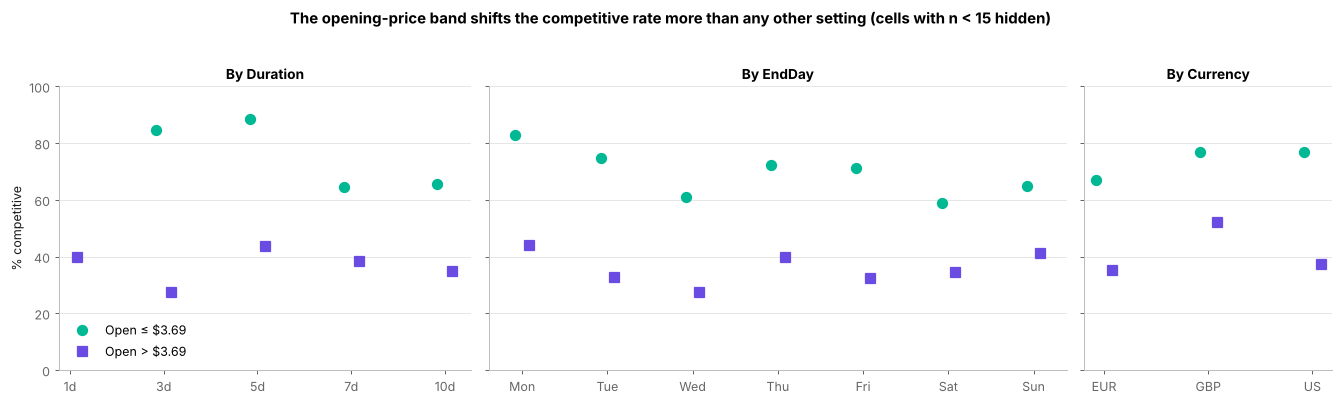


Duration:


,All: % comp,All: n,Open ≤ $3.69: % comp,Open ≤ $3.69: n,Open > $3.69: % comp,Open > $3.69: n
Duration,,,,,,
1,52.2,23,75.0,8,40.0,15
3,45.1,213,84.6,65,27.7,148
5,68.7,466,88.5,260,43.7,206
7,48.9,967,64.7,382,38.6,585
10,54.5,303,65.5,194,34.9,109



EndDay:


,All: % comp,All: n,Open ≤ $3.69: % comp,Open ≤ $3.69: n,Open > $3.69: % comp,Open > $3.69: n
EndDay,,,,,,
Mon,67.3,548,82.9,328,44.1,220
Tue,53.2,171,74.7,83,33.0,88
Wed,48.0,75,60.9,46,27.6,29
Thu,60.4,202,72.4,127,40.0,75
Fri,46.7,287,71.4,105,32.4,182
Sat,42.7,351,59.0,117,34.6,234
Sun,48.5,338,65.0,103,41.3,235



Currency:


,All: % comp,All: n,Open ≤ $3.69: % comp,Open ≤ $3.69: n,Open > $3.69: % comp,Open > $3.69: n
Currency,,,,,,
EUR,55.2,533,66.9,335,35.4,198
GBP,68.7,147,76.8,99,52.1,48
US,51.9,1292,76.8,475,37.5,817


In [20]:
root_feature = FEATURES_PRE[tree_pre.tree_.feature[0]]
OPEN_CUT = tree_pre.tree_.threshold[0] if root_feature == "OpenPrice" else df.OpenPrice.median()
band = np.where(df.OpenPrice <= OPEN_CUT, f"Open ≤ ${OPEN_CUT:.2f}", f"Open > ${OPEN_CUT:.2f}")
band_names = [f"Open ≤ ${OPEN_CUT:.2f}", f"Open > ${OPEN_CUT:.2f}"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True,
                         gridspec_kw={"width_ratios": [5, 7, 3]})
summary_tables = {}
for ax, setting in zip(axes, ["Duration", "EndDay", "Currency"]):
    tab = (df.assign(Band=band).groupby([setting, "Band"], observed=True)["Competitive"]
             .agg(["mean", "size"]).unstack("Band"))
    levels = list(tab.index)
    xs = np.arange(len(levels))
    for (bn, color, mk, off) in zip(band_names, BAND_COLORS, ["o", "s"], [-0.08, 0.08]):
        rates, ns = 100 * tab[("mean", bn)], tab[("size", bn)]
        ok = ns >= 15                                      # hide tiny cells (unstable rates)
        ax.plot(xs[ok] + off, rates[ok], marker=mk, ls="", markersize=8, color=color,
                label=bn.replace("$", "\\$"))
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{l}d" if setting == "Duration" else l for l in levels])
    ax.set_title(f"By {setting}")
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
    t = pd.DataFrame({"All: % comp": (100 * df.groupby(setting, observed=True).Competitive.mean()).round(1),
                      "All: n": df.groupby(setting, observed=True).size()})
    for bn in band_names:
        t[f"{bn}: % comp"] = (100 * tab[("mean", bn)]).round(1)
        t[f"{bn}: n"] = tab[("size", bn)].fillna(0).astype(int)
    summary_tables[setting] = t
axes[0].set_ylabel("% competitive")
axes[0].legend(loc="lower left")
fig.suptitle("The opening-price band shifts the competitive rate more than any other setting "
             "(cells with n < 15 hidden)", fontweight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "07_settings_within_open_price_band.png")
plt.show()

for setting, t in summary_tables.items():
    print(f"\n{setting}:")
    display(t)

### A stricter test: compare each seller with themselves
The tables above still mix *different* sellers. A few large sellers start almost everything at \$0.01–\$0.99, run 5-day auctions and end on Monday (see the seller table in Section 2), so their success gets credited to all three settings at once.

Stricter test: take sellers who used **both** options of a setting (for example, some auctions ending on Monday and some on other days) and compare their competitive rate across the two. If a setting really matters, the same seller should do better when they use it. Each seller is weighted by the smaller of their two group sizes (the number of matched comparisons they can support).

In [21]:
def same_seller_comparison(use_a, label):
    d = df.assign(G=np.where(use_a, "A", "B"))
    raw = d.groupby("G")["Competitive"].mean()
    t = (d.groupby(["SellerRating", "G"])["Competitive"].agg(["mean", "size"])
           .unstack("G").dropna())                                   # sellers who used both options
    diff = t[("mean", "A")] - t[("mean", "B")]
    weight = np.minimum(t[("size", "A")], t[("size", "B")])
    return {"Setting compared (A vs B)": label,
            "Raw difference A − B (pp)": round(100 * (raw["A"] - raw["B"]), 1),
            "Same-seller difference A − B (pp)": round(100 * np.average(diff, weights=weight), 1),
            "Sellers who used both": len(t),
            "Their auctions": int(t[[("size", "A"), ("size", "B")]].to_numpy().sum())}


within = pd.DataFrame([
    same_seller_comparison(df.OpenPrice <= OPEN_CUT, f"Opening price ≤ ${OPEN_CUT:.2f} vs above"),
    same_seller_comparison(df.Duration <= 5, "Duration ≤ 5 days vs 7–10 days"),
    same_seller_comparison(df.EndDay == "Mon", "Ends on Monday vs other days"),
    same_seller_comparison(df.EndDay.isin(["Sat", "Sun"]), "Ends on weekend vs weekday"),
]).set_index("Setting compared (A vs B)")
display(within)

,Raw difference A − B (pp),Same-seller difference A − B (pp),Sellers who used both,Their auctions
Setting compared (A vs B),,,,
Opening price ≤ $3.69 vs above,35.4,10.9,67,656
Duration ≤ 5 days vs 7–10 days,10.7,-4.6,64,495
Ends on Monday vs other days,18.4,4.8,65,699
Ends on weekend vs weekday,-13.0,-3.4,89,799


### What the data say about the seller's settings
* **Opening price is the one setting that holds up.** It is the first split, has the largest importance, and survives the same-seller test. When the *same* seller starts at or below \$3.69, their auctions are about 11 points more likely to be competitive. That is about a third of the raw 35-point gap; the rest reflects *which* items and sellers start low.
* **Duration:** the raw advantage of short auctions (+11 points) **reverses** within sellers (−4.6). The "5-day effect" comes from two large sellers who list at \$0.01–\$0.99 for 5 days, ending on Monday.
* **End day:** Monday's raw lead (67% vs. 43% for Saturday) comes from the same sellers. Within sellers the gap shrinks from 18 points to under 5, and the weekend-vs-weekday gap shrinks from −13 to −3. The tree does not use EndDay at all.
* **Currency/marketplace:** UK (GBP) listings are more competitive in both price bands, but there are only 147 of them and the tree barely uses currency. For most sellers it is not a choice anyway; it reflects where they sell.
* **Caveats:** this is observational data (sellers chose their settings, so it is not an experiment), from eBay in 2004, and *competitive* is not the same as *profitable*.

### Recommendation for a seller
1. **Start low.** With an opening price of about \$1 (or €1/£1) or less, 80–90% of auctions in these data were competitive. Above \$3.69, established sellers were mostly below 40%.
2. **Don't over-engineer duration or end day.** Choose what is convenient; there is no reliable evidence that either matters once you compare like with like.
3. **Protect the value of expensive items.** A low start risks selling cheaply if only two bidders turn up. For valuable items, pair a low opening price with a hidden reserve price. Reserve prices are not in this dataset, so that part is a hypothesis to test, not a finding.
4. **High-volume, high-rated sellers benefit most from changing their starting prices.** Their mid- to high-priced starts were the least competitive group (12–38%).

## 6. Comparison with k-NN
* **Same predictors as Tree 2** (listing-time only) and **the same 60/40 split**, so the classification tables are directly comparable.
* **Pre-processing inside a pipeline:** `log(1+x)` and then standardisation for SellerRating and OpenPrice; dummies stay 0/1. Standardising the dummies would let rare categories (e.g. Photography, n = 13) dominate the distance. The pipeline is fitted on training folds only.
* **Choosing k:** 5-fold cross-validation **on the training set only**. Choosing k on the test set would make the test score optimistic. Only odd k values are tried, which avoids tied votes.

Best k by 5-fold CV on the training set: k = 13 (CV accuracy 69.6%)


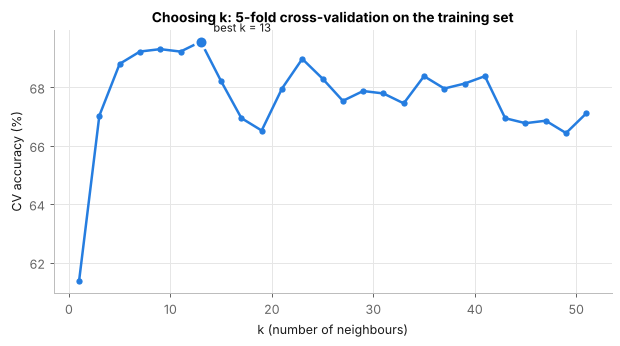

In [22]:
num_cols = ["SellerRating", "OpenPrice"]
dummy_cols = [c for c in FEATURES_PRE if c not in num_cols]
knn_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), num_cols),
        ("dummies", "passthrough", dummy_cols)])),
    ("knn", KNeighborsClassifier())])

k_values = list(range(1, 52, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_acc = [cross_val_score(knn_pipe.set_params(knn__n_neighbors=k), X_train[FEATURES_PRE], y_train,
                          cv=cv, scoring="accuracy").mean() for k in k_values]
best_k = k_values[int(np.argmax(cv_acc))]
print(f"Best k by 5-fold CV on the training set: k = {best_k} (CV accuracy {max(cv_acc):.1%})")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(k_values, np.array(cv_acc) * 100, color=CLASS_COLORS[1], lw=2, marker="o", markersize=4)
ax.plot([best_k], [max(cv_acc) * 100], marker="o", markersize=10, color=CLASS_COLORS[1],
        markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"best k = {best_k}", (best_k, max(cv_acc) * 100), xytext=(10, 8),
            textcoords="offset points", fontsize=9, color=TEXT)
ax.set(xlabel="k (number of neighbours)", ylabel="CV accuracy (%)",
       title="Choosing k: 5-fold cross-validation on the training set")
savefig(fig, "08_knn_choose_k.png")
plt.show()

k-NN (k = 13), test classification table:


,Predicted: Non-competitive,Predicted: Competitive,Total
Actual: Non-competitive,248,114,362
Actual: Competitive,114,313,427
Total,362,427,789


Test-set comparison:


,Naive (always 'Competitive'),"Tree 1 (all, leaky)",Tree 2 (listing-time),"k-NN, k=13 (listing-time)"
Accuracy,0.541,0.820,0.720,0.711
Sensitivity (competitive found),1.000,0.789,0.775,0.733
Specificity (non-competitive found),0.000,0.856,0.655,0.685
Precision (when we say competitive),0.541,0.866,0.726,0.733
AUC,0.500,0.892,0.774,0.770


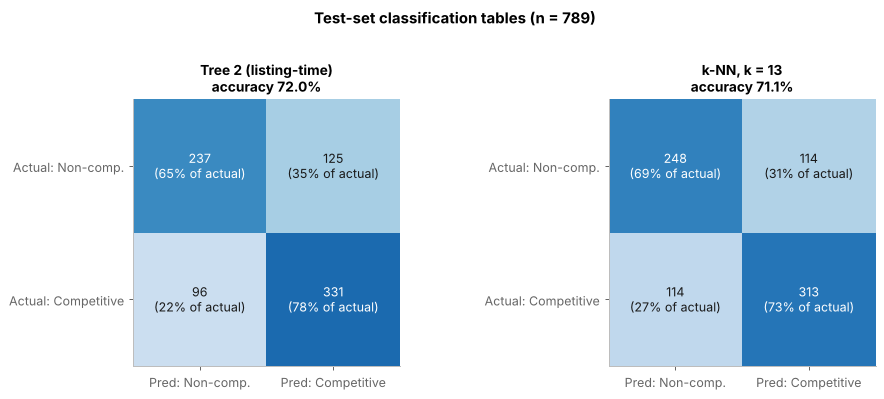

Tree 2 and k-NN give the same prediction for 77.6% of test auctions.


In [23]:
knn = knn_pipe.set_params(knn__n_neighbors=best_k).fit(X_train[FEATURES_PRE], y_train)
pred_knn_test = knn.predict(X_test[FEATURES_PRE])
prob_knn_test = knn.predict_proba(X_test[FEATURES_PRE])[:, 1]
print(f"k-NN (k = {best_k}), test classification table:")
display(classification_table(y_test, pred_knn_test))

comparison = pd.DataFrame({
    "Naive (always 'Competitive')": metrics(y_test, np.ones_like(y_test), np.full(len(y_test), 0.5)),
    "Tree 1 (all, leaky)": metrics(y_test, tree_all.predict(X_test[FEATURES_ALL]),
                                   tree_all.predict_proba(X_test[FEATURES_ALL])[:, 1]),
    "Tree 2 (listing-time)": metrics(y_test, pred_pre_test, prob_pre_test),
    f"k-NN, k={best_k} (listing-time)": metrics(y_test, pred_knn_test, prob_knn_test)}).round(3)
comparison.loc["AUC", "Naive (always 'Competitive')"] = 0.5
print("Test-set comparison:")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (pred, name) in zip(axes, [(pred_pre_test, "Tree 2 (listing-time)"),
                                   (pred_knn_test, f"k-NN, k = {best_k}")]):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    row = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({row[i, j]:.0%} of actual)", ha="center", va="center",
                    color="white" if row[i, j] > 0.6 else TEXT, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred: Non-comp.", "Pred: Competitive"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Actual: Non-comp.", "Actual: Competitive"])
    ax.grid(False)
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_test, pred):.1%}")
fig.suptitle(f"Test-set classification tables (n = {len(y_test)})", fontweight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "09_confusion_tree2_vs_knn.png")
plt.show()

agree = (pred_pre_test == pred_knn_test).mean()
print(f"Tree 2 and k-NN give the same prediction for {agree:.1%} of test auctions.")

### Tree vs. k-NN: trade-offs
* **More predictive?** Essentially a tie on this split: 72.0% vs. 71.1% accuracy and AUC 0.774 vs. 0.770. The tree finds more competitive auctions (77.5% vs. 73.3%), while k-NN is better on non-competitive ones (68.5% vs. 65.5%). The two models agree on 77.6% of test auctions. Over 30 random splits the tree is marginally ahead (70.4% vs. 69.7%), which is within noise.
* **More interpretable?** Clearly the tree. It is 16 if-then rules a manager can read and check. k-NN can only "explain" a prediction as "these 13 past auctions looked similar", and its answers depend on technical choices (scaling, distance measure, k).
* **Business value.** The tree also delivers the actionable insight (start low), and it generalises better to sellers it has never seen (Section 7: 65.7% vs. 60.3%). k-NN leans on near-identical listings from the *same* seller, which is closer to memory than to a pattern. k-NN also has to keep all past auctions and search them for every prediction; that is trivial here but matters at eBay's scale.
* **Verdict:** Tree 2 is the better business tool. It is as accurate, more robust for new sellers, and explainable. k-NN would only be worth revisiting with richer features (for example item condition, photos, or a reserve price) or far more data per seller.

## 7. Robustness checks (appendix material)
1. **Is the result luck of one split?** Re-run both models on 30 different random 60/40 splits.
2. **Will it work for a new seller?** Re-run on 30 *seller-grouped* splits, where no seller appears in both training and test sets. `SellerRating` is used as the seller identifier, which is an approximation.

In [24]:
def run_splits(splitter_name, n=30):
    rows = []
    if splitter_name == "random":
        splits = (train_test_split(np.arange(len(X)), test_size=TEST_SIZE, random_state=s, stratify=y)
                  for s in range(n))
    else:
        splits = GroupShuffleSplit(n_splits=n, test_size=TEST_SIZE,
                                   random_state=RANDOM_STATE).split(X, y, groups=df.SellerRating)
    for tr, te in splits:
        Xtr, Xte, ytr, yte = X.iloc[tr][FEATURES_PRE], X.iloc[te][FEATURES_PRE], y.iloc[tr], y.iloc[te]
        t = DecisionTreeClassifier(min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE).fit(Xtr, ytr)
        k = knn_pipe.set_params(knn__n_neighbors=best_k).fit(Xtr, ytr)
        rows.append({"Tree 2 accuracy": accuracy_score(yte, t.predict(Xte)),
                     "k-NN accuracy": accuracy_score(yte, k.predict(Xte)),
                     "Tree 2 AUC": roc_auc_score(yte, t.predict_proba(Xte)[:, 1]),
                     "k-NN AUC": roc_auc_score(yte, k.predict_proba(Xte)[:, 1]),
                     "Naive accuracy": (yte == ytr.mode()[0]).mean()})
    return pd.DataFrame(rows)


robust = {"Random splits": run_splits("random"), "Seller-grouped splits (new sellers)": run_splits("grouped")}
robust_table = pd.DataFrame({name: r.mean().map("{:.3f}".format) + " ± " + r.std().map("{:.3f}".format)
                             for name, r in robust.items()}).T
print("Mean ± SD over 30 splits:")
display(robust_table)

Mean ± SD over 30 splits:


,Tree 2 accuracy,k-NN accuracy,Tree 2 AUC,k-NN AUC,Naive accuracy
Random splits,0.704 ± 0.011,0.697 ± 0.011,0.767 ± 0.011,0.756 ± 0.012,0.541 ± 0.000
Seller-grouped splits (new sellers),0.657 ± 0.044,0.603 ± 0.038,0.706 ± 0.035,0.633 ± 0.047,0.510 ± 0.052


**Reading the checks**
* **Random splits:** our main split is representative, if slightly favourable. Tree 2 averages 70.4% ± 1.1 across 30 splits, compared with 72.0% on the reported split.
* **New sellers:** when no seller appears in both the training and test sets, accuracy falls to **65.7% for the tree and 60.3% for k-NN** (guessing: 51.0%). For an auction from a seller the model has never seen, realistic accuracy is about two-thirds. That is still well above guessing, but the headline 72% is optimistic. The report should give the required 72% and state this caveat.

## 8. Key numbers for the report

In [25]:
key = {
    "Auctions": len(df),
    "Share competitive": f"{df.Competitive.mean():.1%}",
    "Tree 1 test accuracy (leaky, not usable)": f"{comparison.loc['Accuracy', 'Tree 1 (all, leaky)']:.1%}",
    "Tree 2 test accuracy": f"{comparison.loc['Accuracy', 'Tree 2 (listing-time)']:.1%}",
    f"k-NN (k={best_k}) test accuracy": f"{comparison.iloc[0, 3]:.1%}",
    "Naive benchmark accuracy": f"{naive_acc:.1%}",
    "Tree 2 first split (opening price)": f"${OPEN_CUT:.2f}",
    "Tree 2 accuracy, new sellers (grouped)": robust_table.loc["Seller-grouped splits (new sellers)", "Tree 2 accuracy"],
}
display(pd.Series(key, name="Value").to_frame())
print("Figures saved in ./figures:", sorted(os.listdir(FIG_DIR)))

,Value
Auctions,1972
Share competitive,54.1%
"Tree 1 test accuracy (leaky, not usable)",82.0%
Tree 2 test accuracy,72.0%
k-NN (k=13) test accuracy,71.1%
Naive benchmark accuracy,54.1%
Tree 2 first split (opening price),$3.69
"Tree 2 accuracy, new sellers (grouped)",0.657 ± 0.044


Figures saved in ./figures: ['01_rate_by_categorical.png', '02_rate_by_numeric_decile.png', '03_leakage_close_vs_open.png', '04_tree1_all_predictors.png', '05_tree2_listing_time.png', '06_tree2_scatter_partition.png', '07_settings_within_open_price_band.png', '08_knn_choose_k.png', '09_confusion_tree2_vs_knn.png']


## Summary of findings (a starting point for the Executive Summary)
1. **Data:** 1,972 auctions, 54% competitive. Three summary rows under the data were removed. All prices are already in USD, so Currency marks the marketplace.
2. **Tree 1 (all predictors)** reaches 82% test accuracy but **cannot be used**: ClosePrice is only known after the auction ends. The single rule "closed above the opening price" scores 96%.
3. **Tree 2 (listing-time predictors)** reaches **72% on the test set vs. 54% by guessing**. Almost all of its power comes from **opening price and seller rating**.
4. **Opening price is the main lever.** Starting at about \$1 or less gives an 80–90% chance of a competitive auction; above \$3.69, most auctions from established sellers are not competitive. The effect holds up when a seller is compared with themselves.
5. **Duration, end day and currency only look important in raw tables.** That reflects who uses them (a handful of large sellers), and the effects disappear when sellers are compared with themselves.
6. **k-NN (k = 13)** is about as accurate (71%) but is less explainable and generalises worse to new sellers (60% vs. 66%).
7. **Recommendation:** start low (with a reserve price for valuable items). Pick duration and end day for convenience. Expect about two-thirds accuracy for a brand-new seller.